# Chapter 37: Ensembles and the ideal denoiser

Checks [chapter 37](../../book/37-ensembles-and-the-denoiser.md), whose Lean is `Averaging.lean`. Three kinds of model appear.
**Members of an ensemble** are linear in their weights: fixed sine and cosine features of frequencies 1 to 10 with
learned coefficients, fitted by ridge regression to a bootstrap resample of 40 noisy points (the model the weight-averaging
theorem is about). **The two-layer control** multiplies two weights, which is not linear in them. **The ideal denoiser**
is the attention head of the chapter, written out in NumPy. Everything is float64 and seeded.
Where a number comes from evaluating the chapter's formula (random numbers, hand examples, the denoiser's own formula) and not from a fit or a sampled model, the check says "from the formula"; a check whose truth the code forces is printed as "by construction, cannot fail" and is not counted. These are checks, not proofs: the proofs are in `Averaging.lean` and `ModeConnectivity.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from scipy.optimize import linprog, minimize
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE, DATA
import matplotlib.pyplot as plt

use_style()
SEED = 37
NUM_FREQUENCIES = 10
NUM_TRAIN = 40
TRAIN_NOISE = 0.3
RIDGE = 0.05
TWO_PI = 2.0 * np.pi


def target_function(inputs):
    return np.sin(inputs) + 0.5 * np.sin(3.0 * inputs)


def make_features(inputs, derivative=False):
    # A constant column, then cos(k x) and sin(k x) for k = 1..NUM_FREQUENCIES. The model is linear in its weights.
    columns = [np.zeros_like(inputs) if derivative else np.ones_like(inputs)]
    for frequency in range(1, NUM_FREQUENCIES + 1):
        if derivative:
            columns.append(-frequency * np.sin(frequency * inputs))
            columns.append(frequency * np.cos(frequency * inputs))
        else:
            columns.append(np.cos(frequency * inputs))
            columns.append(np.sin(frequency * inputs))
    return np.stack(columns, axis=1)


def fit_member(generator):
    # One member: ridge regression on a bootstrap resample of the noisy training set.
    chosen = generator.integers(0, NUM_TRAIN, size=NUM_TRAIN)
    features = make_features(TRAIN_INPUTS[chosen])
    labels = TRAIN_LABELS[chosen]
    gram = features.T @ features + RIDGE * np.eye(features.shape[1])
    return np.linalg.solve(gram, features.T @ labels)


generator = np.random.default_rng(SEED)
TRAIN_INPUTS = generator.uniform(0.0, TWO_PI, NUM_TRAIN)
TRAIN_LABELS = target_function(TRAIN_INPUTS) + TRAIN_NOISE * generator.standard_normal(NUM_TRAIN)
TEST_INPUTS = np.linspace(0.0, TWO_PI, 400)
TEST_LABELS = target_function(TEST_INPUTS)           # the label each test input should get
TEST_FEATURES = make_features(TEST_INPUTS)
SLOPE_INPUTS = np.linspace(0.0, TWO_PI, 20001)
SLOPE_FEATURES = make_features(SLOPE_INPUTS, derivative=True)

NUM_MEMBERS = 30
member_weights = np.stack([fit_member(generator) for _ in range(NUM_MEMBERS)])        # (members, features)
member_predictions = member_weights @ TEST_FEATURES.T                                  # (members, test inputs)
member_errors = ((member_predictions - TEST_LABELS) ** 2).mean(axis=1)
print(f"{NUM_MEMBERS} members; squared error of a single member on the test inputs: "
      f"mean {member_errors.mean():.4f}, range {member_errors.min():.4f} to {member_errors.max():.4f}")

30 members; squared error of a single member on the test inputs: mean 0.7103, range 0.1540 to 2.3052


## Claim 1: the squared error of an average is the average squared error minus the spread (`error_of_the_average_equals_average_error_minus_spread`)

First the example of the chapter, predictions 8 and 14 for a label 10 with shares one half, and the check-yourself
question, predictions 1, 2 and 6 for a label 3. Then 2000 random cases: 2 to 9 members, random predictions, a random label,
random positive shares that sum to one. **Prediction:** the two sides agree to rounding error, about `1e-12` for numbers of
size 10. A difference above `1e-9` would count against the claim.

The control breaks the hypothesis that the shares sum to one: the same cases with shares that sum to 1.5. The identity is
then only an equation between two different numbers, so the two sides should differ, by a lot.

In [2]:
def split_blend_error(shares, predictions, label):
    blend = np.sum(shares * predictions)
    blend_error = (blend - label) ** 2
    average_error = np.sum(shares * (predictions - label) ** 2)
    spread = np.sum(shares * (predictions - blend) ** 2)
    return blend, blend_error, average_error, spread


blend, blend_error, average_error, spread = split_blend_error(np.array([0.5, 0.5]), np.array([8.0, 14.0]), 10.0)
report("from the formula: hand example: blend 11, error of the blend 1, average error 10, spread 9",
       (blend, blend_error, average_error, spread) == (11.0, 1.0, 10.0, 9.0),
       f"blend {blend}, error {blend_error}, average error {average_error}, spread {spread}")
third_shares = np.full(3, 1.0 / 3.0)
_, _, average_error, spread = split_blend_error(third_shares, np.array([1.0, 2.0, 6.0]), 3.0)
report("from the formula: check yourself: blend 3, average error 14/3, spread 14/3",
       abs(average_error - 14 / 3) < 1e-12 and abs(spread - 14 / 3) < 1e-12, f"spread {spread:.4f}")

generator = np.random.default_rng(SEED + 1)
worst_gap = 0.0
worst_gap_control = 0.0
for _ in range(2000):
    count = int(generator.integers(2, 10))
    shares = generator.dirichlet(np.ones(count))
    predictions = 10.0 * generator.standard_normal(count)
    label = 10.0 * generator.standard_normal()
    _, blend_error, average_error, spread = split_blend_error(shares, predictions, label)
    worst_gap = max(worst_gap, abs(blend_error - (average_error - spread)))
    _, blend_error, average_error, spread = split_blend_error(1.5 * shares, predictions, label)
    worst_gap_control = max(worst_gap_control, abs(blend_error - (average_error - spread)))
report("from the formula: error of the blend = average error - spread, in 2000 random cases", worst_gap < 1e-9, f"largest gap {worst_gap:.1e}")
report("from the formula: control: shares summing to 1.5 break the identity", worst_gap_control > 1.0, f"largest gap {worst_gap_control:.1f}")

[PASS] from the formula: hand example: blend 11, error of the blend 1, average error 10, spread 9  (blend 11.0, error 1.0, average error 10.0, spread 9.0)
[PASS] from the formula: check yourself: blend 3, average error 14/3, spread 14/3  (spread 4.6667)
[PASS] from the formula: error of the blend = average error - spread, in 2000 random cases  (largest gap 6.8e-13)
[PASS] from the formula: control: shares summing to 1.5 break the identity  (largest gap 915.2)


True

## Claim 2: with positive shares the blend is at least as good as the members are on average (`ensemble_error_is_at_most_average_member_error`)

Take the 30 fitted members. For each number of members `count` from 1 to 30, average the first `count` with equal shares and
measure the squared error on 400 test inputs, against the labels. **Prediction:** at every `count` the error of the blend is no
more than the average error of those members, and the gap equals the spread (the average over test inputs of the share-weighted
squared distance of the members from the blend), to rounding error. The members are bootstrap fits with different noise in
their data, so they disagree between data points: the error of the blend should also fall below that of a single member as
`count` grows. If it stayed level, the ensemble would gain nothing here, which counts against "the gain is the disagreement".

The control breaks the positive shares. Take two members with shares 1.5 and -0.5, which still sum to one. The identity still
holds, but the spread is then counted with a negative share, so the blend should be *worse* than the average error.

In [3]:
counts = np.arange(1, NUM_MEMBERS + 1)
blend_errors, bounds, spreads = [], [], []
for count in counts:
    shares = np.full(count, 1.0 / count)
    predictions = member_predictions[:count]
    blend = shares @ predictions
    blend_errors.append(((blend - TEST_LABELS) ** 2).mean())
    bounds.append((shares @ (predictions - TEST_LABELS) ** 2).mean())
    spreads.append((shares @ (predictions - blend) ** 2).mean())
blend_errors, bounds, spreads = map(np.array, (blend_errors, bounds, spreads))

report("the blend is never worse than the average error of its members, for 1 to 30 members",
       bool(np.all(blend_errors <= bounds + 1e-12)), f"largest excess {np.max(blend_errors - bounds):.1e}")
report("the gain equals the spread, to rounding error",
       bool(np.max(np.abs((bounds - blend_errors) - spreads)) < 1e-10),
       f"largest gap {np.max(np.abs((bounds - blend_errors) - spreads)):.1e}")
report("30 models average to a lower error than one model",
       blend_errors[-1] < blend_errors[0],
       f"one model {blend_errors[0]:.4f}, 30 models {blend_errors[-1]:.4f}, spread at 30 {spreads[-1]:.4f}")

negative_shares = np.array([1.5, -0.5])
negative_blend = negative_shares @ member_predictions[:2]
negative_blend_error = ((negative_blend - TEST_LABELS) ** 2).mean()
negative_average_error = (negative_shares @ (member_predictions[:2] - TEST_LABELS) ** 2).mean()
negative_spread = (negative_shares @ (member_predictions[:2] - negative_blend) ** 2).mean()
report("from the formula: control: with a negative share the identity still holds",
       abs(negative_blend_error - (negative_average_error - negative_spread)) < 1e-10)
report("control: with a negative share the blend is worse than the average error",
       negative_blend_error > negative_average_error,
       f"blend {negative_blend_error:.4f}, average error {negative_average_error:.4f}, spread {negative_spread:.4f}")

[PASS] the blend is never worse than the average error of its members, for 1 to 30 members  (largest excess 0.0e+00)
[PASS] the gain equals the spread, to rounding error  (largest gap 2.2e-16)
[PASS] 30 models average to a lower error than one model  (one model 0.3781, 30 models 0.2063, spread at 30 0.5040)
[PASS] from the formula: control: with a negative share the identity still holds
[PASS] control: with a negative share the blend is worse than the average error  (blend 1.3045, average error 0.1409, spread -1.1637)


True

## Claim 3: the blend is no steeper than its steepest member (`average_slope_is_at_most_steepest_member`)

The slope of each fitted member is its derivative, computed exactly from the features, on 20001 inputs over one period.
**Prediction:** the steepest slope of the equal-share blend of all 30 members is no more than the steepest slope among the
members. The control breaks the positive shares: for each of the 870 ordered pairs of members, shares 1.5 and -0.5 (which still sum to one).
That blend is no steeper than the steeper of the two only if the slope bound survives negative shares; it should not,
in a good share of the pairs. (Shares summing to 2 are a poorer control here: the members disagree, so twice their average
stays below the steepest member.)

In [4]:
member_slopes = np.abs(member_weights @ SLOPE_FEATURES.T).max(axis=1)         # steepest slope of each member
equal_shares = np.full(NUM_MEMBERS, 1.0 / NUM_MEMBERS)
blend_slope = np.abs((equal_shares @ member_weights) @ SLOPE_FEATURES.T).max()
steeper_pairs = 0
total_pairs = 0
for first in range(NUM_MEMBERS):
    for second in range(NUM_MEMBERS):
        if first != second:
            pair_weights = 1.5 * member_weights[first] - 0.5 * member_weights[second]
            pair_slope = np.abs(pair_weights @ SLOPE_FEATURES.T).max()
            steeper_pairs += pair_slope > max(member_slopes[first], member_slopes[second])
            total_pairs += 1
report("the blend is no steeper than its steepest member",
       blend_slope <= member_slopes.max() + 1e-12,
       f"blend {blend_slope:.3f}, steepest member {member_slopes.max():.3f}, mean member {member_slopes.mean():.3f}")
report("control: with shares 1.5 and -0.5 the blend is steeper than both members in over half the pairs",
       steeper_pairs > total_pairs / 2, f"{steeper_pairs} of {total_pairs} pairs")

[PASS] the blend is no steeper than its steepest member  (blend 10.202, steepest member 26.143, mean member 14.291)
[PASS] control: with shares 1.5 and -0.5 the blend is steeper than both members in over half the pairs  (619 of 870 pairs)


True

## Claim 4: for a model linear in its weights, averaging the weights is averaging the lines (`averaging_weights_is_averaging_lines`, `averaged_weights_error_is_at_most_average_member_error`)

Average the 30 weight vectors with equal shares and predict with the averaged weights. **Prediction:** the prediction equals the
average of the 30 predictions to rounding error, and its error is no more than the average error of the members.

The control is the two-layer model of `halfway_to_the_mirror_image_everything_is_lost`, which multiplies two weights, so it is not linear in them:
`output = first_weight * second_weight * input`. Train it by gradient descent on the target `0.91 * input`, once from the
starting weights `(0.5, 1.0)` and once from the mirror image `(-0.5, -1.0)`. **Prediction:** both runs fit to a small error, they
end at weights of opposite sign, and the midpoint of the two weight pairs has an error far above that of either fit. (That the
output at the exact midpoint is zero, whatever the fit, is the formula of the theorem; the trained runs only show that the
fits land on the two sides.)

In [5]:
soup_weights = equal_shares @ member_weights
soup_prediction = TEST_FEATURES @ soup_weights
blend_prediction = equal_shares @ member_predictions
soup_error = ((soup_prediction - TEST_LABELS) ** 2).mean()
report("averaged weights give the average of the predictions",
       np.max(np.abs(soup_prediction - blend_prediction)) < 1e-10,
       f"largest gap {np.max(np.abs(soup_prediction - blend_prediction)):.1e}")
report("averaged weights are no worse than the members are on average",
       soup_error <= member_errors.mean(),
       f"soup {soup_error:.4f}, average member {member_errors.mean():.4f}")

line_inputs = np.linspace(-2.0, 2.0, 41)
line_target = 0.91 * line_inputs


def run_two_layer(first_weight, second_weight, inputs):
    return first_weight * second_weight * inputs


def train_two_layer(first_weight, second_weight, steps=4000, learning_rate=0.05):
    for _ in range(steps):
        residual = run_two_layer(first_weight, second_weight, line_inputs) - line_target
        first_gradient = np.mean(2.0 * residual * second_weight * line_inputs)
        second_gradient = np.mean(2.0 * residual * first_weight * line_inputs)
        first_weight, second_weight = first_weight - learning_rate * first_gradient, second_weight - learning_rate * second_gradient
    return first_weight, second_weight


fit_weights = train_two_layer(0.5, 1.0)
mirror_weights = train_two_layer(-0.5, -1.0)
fit_error = np.mean((run_two_layer(*fit_weights, line_inputs) - line_target) ** 2)
mirror_error = np.mean((run_two_layer(*mirror_weights, line_inputs) - line_target) ** 2)
midpoint_weights = tuple((np.array(fit_weights) + np.array(mirror_weights)) / 2.0)
midpoint_error = np.mean((run_two_layer(*midpoint_weights, line_inputs) - line_target) ** 2)
report("control, trained: two runs fit from opposite starts and the midpoint of their weights does not",
       fit_error < 1e-6 and mirror_error < 1e-6 and fit_weights[0] * mirror_weights[0] < 0 and midpoint_error > 0.1,
       f"fit weights {fit_weights[0]:.3f}, {fit_weights[1]:.3f}, mirror weights {mirror_weights[0]:.3f}, {mirror_weights[1]:.3f}, "
       f"fit error {fit_error:.1e}, mirror error {mirror_error:.1e}, midpoint error {midpoint_error:.3f}")


[PASS] averaged weights give the average of the predictions  (largest gap 6.7e-16)
[PASS] averaged weights are no worse than the members are on average  (soup 0.2063, average member 0.7103)
[PASS] control, trained: two runs fit from opposite starts and the midpoint of their weights does not  (fit weights 0.782, 1.164, mirror weights -0.782, -1.164, fit error 7.6e-32, mirror error 7.6e-32, midpoint error 1.159)


True

## Claim 5: the weighted mean is the best single guess (`weighted_mean_is_the_best_single_guess`, `weighted_squared_distance_splits_at_the_mean`)

In three dimensions, with 6 points and random positive shares summing to one, the share-weighted squared distance to any
point `other` should be the weighted squared distance to the weighted mean plus `‖mean - other‖²`, exactly. **Prediction:**
the split holds to rounding error in 500 random cases, no random point beats the mean, and a numerical minimiser started
away from the mean ends at the mean (to `1e-5`). The control uses the *unweighted* mean when the shares are not equal: it is
not the minimiser, and it should lose by exactly the share-weighted squared distance from the weighted mean.

In [6]:
generator = np.random.default_rng(SEED + 2)
worst_split_gap = 0.0
beaten = 0
worst_distance_to_mean = 0.0
worst_control_gap = 0.0
control_losses = []
for _ in range(500):
    points = generator.standard_normal((6, 3))
    shares = generator.dirichlet(np.ones(6))
    weighted_mean = shares @ points

    def weighted_squared_distance(other):
        return np.sum(shares * np.sum((points - other) ** 2, axis=1))

    for other in generator.standard_normal((20, 3)) * 2.0:
        split = weighted_squared_distance(weighted_mean) + np.sum((weighted_mean - other) ** 2)
        worst_split_gap = max(worst_split_gap, abs(weighted_squared_distance(other) - split))
        beaten += weighted_squared_distance(other) < weighted_squared_distance(weighted_mean) - 1e-12
    unweighted_mean = points.mean(axis=0)
    control_loss = weighted_squared_distance(unweighted_mean) - weighted_squared_distance(weighted_mean)
    control_losses.append(control_loss)
    worst_control_gap = max(worst_control_gap, abs(control_loss - np.sum((weighted_mean - unweighted_mean) ** 2)))
    if len(control_losses) <= 50:
        found = minimize(weighted_squared_distance, generator.standard_normal(3) * 3.0, tol=1e-12).x
        worst_distance_to_mean = max(worst_distance_to_mean, np.linalg.norm(found - weighted_mean))
report("from the formula: weighted squared distance to any point = distance to the weighted mean + squared distance from the mean",
       worst_split_gap < 1e-10, f"largest gap {worst_split_gap:.1e}")
report("from the formula: no random point beats the weighted mean (10000 points)", beaten == 0, f"{beaten} beat it")
report("a numerical minimiser ends at the weighted mean", worst_distance_to_mean < 1e-5, f"farthest {worst_distance_to_mean:.1e}")
report("from the formula: control: the unweighted mean loses, by exactly the squared distance to the weighted mean",
       min(control_losses) >= 0 and worst_control_gap < 1e-10 and np.mean(control_losses) > 0.01,
       f"mean loss {np.mean(control_losses):.3f}, largest formula gap {worst_control_gap:.1e}")

[PASS] from the formula: weighted squared distance to any point = distance to the weighted mean + squared distance from the mean  (largest gap 2.8e-14)
[PASS] from the formula: no random point beats the weighted mean (10000 points)  (0 beat it)
[PASS] a numerical minimiser ends at the weighted mean  (farthest 3.6e-08)
[PASS] from the formula: control: the unweighted mean loses, by exactly the squared distance to the weighted mean  (mean loss 0.356, largest formula gap 3.1e-15)


True

## Claim 6: the ideal denoiser is an attention head, with the two worked examples (`DENOISE_IDEALLY`, `ideal_denoiser_equals_weighted_mean_of_examples`)

`denoise_ideally` below scores each training example by `-‖noisy_input - example‖² / (2 * noise_level²)`, turns the scores
into shares with a softmax and returns the weighted mean. **Prediction:** the examples 0 and 4 with a noisy input 1 give
shares 0.982 and 0.018 and the output 0.07 at `noise_level` 1, and shares 0.51 and 0.49 and the output 1.96 at `noise_level`
10. A noisy input at 2, half way, gives exactly 2.

In [7]:
def get_shares(noisy_input, examples, noise_level):
    squared_distances = np.sum((examples - noisy_input) ** 2, axis=-1)
    scores = -squared_distances / (2.0 * noise_level ** 2)
    scores = scores - scores.max()                         # the softmax is unchanged by this shift
    weights = np.exp(scores)
    return weights / weights.sum()


def denoise_ideally(noisy_input, examples, noise_level):
    return get_shares(noisy_input, examples, noise_level) @ examples


line_examples = np.array([[0.0], [4.0]])
rows = {}
for noise_level in (1.0, 10.0):
    shares = get_shares(np.array([1.0]), line_examples, noise_level)
    rows[noise_level] = (shares, denoise_ideally(np.array([1.0]), line_examples, noise_level)[0])
report("from the formula: noise level 1: shares 0.982 and 0.018, output 0.07",
       abs(rows[1.0][0][0] - 0.982) < 5e-4 and abs(rows[1.0][1] - 0.07) < 5e-3,
       f"shares {rows[1.0][0].round(4)}, output {rows[1.0][1]:.4f}")
report("from the formula: noise level 10: shares 0.51 and 0.49, output 1.96",
       abs(rows[10.0][0][0] - 0.51) < 5e-3 and abs(rows[10.0][1] - 1.96) < 5e-3,
       f"shares {rows[10.0][0].round(4)}, output {rows[10.0][1]:.4f}")
half_way = denoise_ideally(np.array([2.0]), line_examples, 1.0)[0]
report("from the formula: half way between 0 and 4 the output is 2", abs(half_way - 2.0) < 1e-12, f"output {half_way:.12f}")

[PASS] from the formula: noise level 1: shares 0.982 and 0.018, output 0.07  (shares [0.982 0.018], output 0.0719)
[PASS] from the formula: noise level 10: shares 0.51 and 0.49, output 1.96  (shares [0.51 0.49], output 1.9600)
[PASS] from the formula: half way between 0 and 4 the output is 2  (output 2.000000000000)


True

## Claim 7: no other output is closer to the examples on the share-weighted squared distance (`ideal_denoiser_is_the_best_guess`)

Twelve training examples in the plane, 300 random noisy inputs, each at a random noise level between 0.3 and 3. For each, the
share-weighted spread of the examples round the denoiser's output is compared with that round (a) 200 random outputs, (b) the
plain mean of the examples, (c) the nearest example, and (d) the ideal denoiser *at a different noise level* (three times the
true one). **Prediction:** the denoiser never has a larger spread than any of them, and the excess of each other output is
exactly `‖other - denoised‖²`. The control is (d): a denoiser at the wrong noise level should lose, and by how much we report.

In [8]:
generator = np.random.default_rng(SEED + 3)
plane_examples = generator.standard_normal((12, 2)) * 2.0
beaten = 0
worst_excess_gap = 0.0
wrong_level_losses = []
for _ in range(300):
    noise_level = float(np.exp(generator.uniform(np.log(0.3), np.log(3.0))))
    noisy_input = generator.standard_normal(2) * 3.0
    shares = get_shares(noisy_input, plane_examples, noise_level)
    denoised = shares @ plane_examples

    def get_spread(output):
        return np.sum(shares * np.sum((plane_examples - output) ** 2, axis=1))

    denoiser_spread = get_spread(denoised)
    others = list(generator.standard_normal((200, 2)) * 3.0)
    others.append(plane_examples.mean(axis=0))
    others.append(plane_examples[np.argmin(np.sum((plane_examples - noisy_input) ** 2, axis=1))])
    wrong_level = denoise_ideally(noisy_input, plane_examples, 3.0 * noise_level)
    others.append(wrong_level)
    for other in others:
        beaten += get_spread(other) < denoiser_spread - 1e-12
        worst_excess_gap = max(worst_excess_gap, abs(get_spread(other) - denoiser_spread - np.sum((other - denoised) ** 2)))
    wrong_level_losses.append(get_spread(wrong_level) - denoiser_spread)
report("from the formula: the ideal denoiser is never beaten, against 203 other outputs for each of 300 inputs", beaten == 0, f"{beaten} beat it")
report("from the formula: each other output loses by exactly the squared distance from the denoiser's output", worst_excess_gap < 1e-10,
       f"largest gap {worst_excess_gap:.1e}")
report("from the formula: control: a denoiser at three times the noise level loses",
       min(wrong_level_losses) >= 0 and np.mean(wrong_level_losses) > 0.01,
       f"mean loss {np.mean(wrong_level_losses):.3f}, largest {max(wrong_level_losses):.3f}")

[PASS] from the formula: the ideal denoiser is never beaten, against 203 other outputs for each of 300 inputs  (0 beat it)
[PASS] from the formula: each other output loses by exactly the squared distance from the denoiser's output  (largest gap 8.5e-14)
[PASS] from the formula: control: a denoiser at three times the noise level loses  (mean loss 1.368, largest 5.902)


True

## Claim 8: the output never leaves the region the examples span (`ideal_denoiser_stays_inside_the_examples`)

In one dimension the hull is the stretch from the smallest to the largest example; in the plane it is checked by a linear
program that looks for shares, non-negative and summing to one, that reproduce the output. **Prediction:** in 3000 random cases
in one dimension, and 300 in the plane, the output is inside, including at the extreme noise levels 0.05 and 50. The control
removes the softmax's normalisation: `sum(exp(score) * example)` with no division. With examples far from the origin the
output should leave the hull.

In [9]:
generator = np.random.default_rng(SEED + 4)
outside_line = 0
for _ in range(3000):
    line_points = generator.standard_normal((int(generator.integers(2, 9)), 1)) * 3.0
    noise_level = float(np.exp(generator.uniform(np.log(0.05), np.log(50.0))))
    noisy_input = generator.standard_normal(1) * 6.0
    output = denoise_ideally(noisy_input, line_points, noise_level)[0]
    outside_line += not (line_points.min() - 1e-12 <= output <= line_points.max() + 1e-12)


def is_in_hull(point, points):
    # Is there a share vector, all non-negative and summing to one, with shares @ points = point?
    count = len(points)
    equations = np.vstack([points.T, np.ones((1, count))])
    targets = np.append(point, 1.0)
    result = linprog(np.zeros(count), A_eq=equations, b_eq=targets, bounds=[(0, None)] * count, method="highs")
    return result.status == 0


outside_plane = 0
outside_control = 0
for _ in range(300):
    plane_points = generator.standard_normal((6, 2)) + np.array([5.0, 5.0])        # far from the origin
    noise_level = float(np.exp(generator.uniform(np.log(0.05), np.log(50.0))))
    noisy_input = generator.standard_normal(2) * 6.0 + np.array([5.0, 5.0])
    outside_plane += not is_in_hull(denoise_ideally(noisy_input, plane_points, noise_level), plane_points)
    raw_scores = -np.sum((plane_points - noisy_input) ** 2, axis=1) / (2.0 * noise_level ** 2)
    unnormalised = np.exp(raw_scores) @ plane_points
    outside_control += not is_in_hull(unnormalised, plane_points)
report("from the formula: in one dimension the output stays between the smallest and largest example (3000 cases)",
       outside_line == 0, f"{outside_line} outside")
report("from the formula: in the plane the output stays in the convex hull (300 cases, extreme noise levels included)",
       outside_plane == 0, f"{outside_plane} outside")
report("from the formula: control: without the division the output leaves the hull in most cases", outside_control > 150,
       f"{outside_control} of 300 outside")

[PASS] from the formula: in one dimension the output stays between the smallest and largest example (3000 cases)  (0 outside)
[PASS] from the formula: in the plane the output stays in the convex hull (300 cases, extreme noise levels included)  (0 outside)
[PASS] from the formula: control: without the division the output leaves the hull in most cases  (299 of 300 outside)


True

## Recalled, not proved: the shares are the softmax because of Bayes' rule

The chapter recalls that, with Gaussian noise, these shares are the probability that each example was the clean one. That is
not proved there. The simulation below is evidence for it, not a proof. Five one-dimensional examples. Draw a clean example
uniformly, add Gaussian noise of standard deviation 1, and keep the draws whose noisy value falls within 0.05 of a chosen value.
The mean of the clean examples among the kept draws should match the ideal denoiser at that value to within four standard
errors. **Prediction:** it does at all five chosen values. The control is the same comparison against the denoiser at three
times the noise level, which should miss by many standard errors at some value.

In [10]:
generator = np.random.default_rng(SEED + 5)
bayes_examples = np.array([[-3.0], [-1.0], [0.5], [2.0], [4.0]])
NOISE_LEVEL = 1.0
NUM_DRAWS = 4_000_000
clean = generator.integers(0, 5, size=NUM_DRAWS)
noisy = bayes_examples[clean, 0] + NOISE_LEVEL * generator.standard_normal(NUM_DRAWS)
worst_standard_errors = 0.0
worst_control_errors = 0.0
for chosen in (-2.0, -0.5, 1.0, 2.5, 4.0):
    kept = np.abs(noisy - chosen) < 0.05
    clean_values = bayes_examples[clean[kept], 0]
    standard_error = clean_values.std() / np.sqrt(kept.sum())
    ideal = denoise_ideally(np.array([chosen]), bayes_examples, NOISE_LEVEL)[0]
    wrong = denoise_ideally(np.array([chosen]), bayes_examples, 3.0 * NOISE_LEVEL)[0]
    worst_standard_errors = max(worst_standard_errors, abs(clean_values.mean() - ideal) / standard_error)
    worst_control_errors = max(worst_control_errors, abs(clean_values.mean() - wrong) / standard_error)
    print(f"noisy value {chosen:5.1f}: {kept.sum():7d} draws, mean clean example {clean_values.mean():7.3f}, "
          f"ideal denoiser {ideal:7.3f}, wrong-level denoiser {wrong:7.3f}, standard error {standard_error:.3f}")
report("the mean clean example matches the ideal denoiser within four standard errors",
       worst_standard_errors < 4.0, f"largest gap {worst_standard_errors:.2f} standard errors")
report("control: the denoiser at three times the noise level is far off at some value",
       worst_control_errors > 10.0, f"largest gap {worst_control_errors:.1f} standard errors")

noisy value  -2.0:   40436 draws, mean clean example  -1.914, ideal denoiser  -1.912, wrong-level denoiser  -0.657, standard error 0.005
noisy value  -0.5:   49924 draws, mean clean example  -0.395, ideal denoiser  -0.395, wrong-level denoiser   0.021, standard error 0.004
noisy value   1.0:   52080 draws, mean clean example   0.949, ideal denoiser   0.955, wrong-level denoiser   0.740, standard error 0.004


noisy value   2.5:   42552 draws, mean clean example   2.328, ideal denoiser   2.327, wrong-level denoiser   1.439, standard error 0.005
noisy value   4.0:   35943 draws, mean clean example   3.758, ideal denoiser   3.755, wrong-level denoiser   2.062, standard error 0.003
[PASS] the mean clean example matches the ideal denoiser within four standard errors  (largest gap 1.51 standard errors)
[PASS] control: the denoiser at three times the noise level is far off at some value  (largest gap 487.2 standard errors)


True

## Figure 1: the error of an average of models against the number of models

Drawn from claim 2, with fitted models (measured). The purple curve is the squared error of the blend of the first `count` members. The green curve is the
average squared error of those same members, the bound of `ensemble_error_is_at_most_average_member_error`. The black circles are that average error minus the
spread, computed separately: they should sit on the purple curve, which is the identity of claim 1.

wrote book/figures/37-error-of-an-average.png


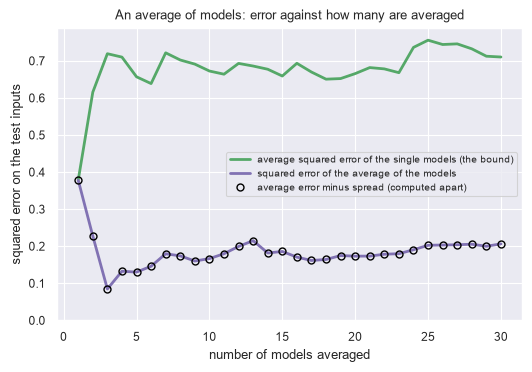

In [11]:
use_style()
figure, axis = plt.subplots(figsize=(6.0, 3.8))
axis.plot(counts, bounds, color=BOUND, linewidth=2, label="average squared error of the single models (the bound)")
axis.plot(counts, blend_errors, color=MODEL, linewidth=2, label="squared error of the average of the models")
axis.plot(counts, bounds - spreads, "o", markerfacecolor="none", markeredgecolor=DATA, markersize=5,
          label="average error minus spread (computed apart)")
axis.set_xlabel("number of models averaged")
axis.set_ylabel("squared error on the test inputs")
axis.set_title("An average of models: error against how many are averaged")
axis.set_ylim(bottom=0.0)
axis.legend(loc="center right", fontsize=7)
save_figure(figure, "37-error-of-an-average")
plt.show()

## Figure 2: the ideal denoiser as an average of the data points, at three noise levels

This figure is **from the formula**: it evaluates `denoise_ideally`, it is not a fit or a sample. Five one-dimensional training examples (the same as in the Bayes check). For each noisy input from -8 to 10 the purple curve
is the output of `denoise_ideally`. The grey line is the output that does nothing, the noisy input itself. The black ticks on
the right edge mark the examples.

wrote book/figures/37-ideal-denoiser.png


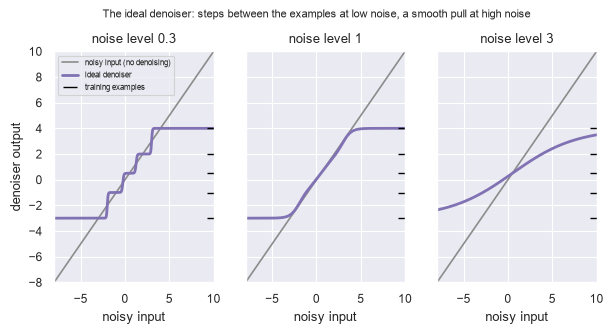

noise level 0.3: output range -3.000 to 4.000, example range -3.0 to 4.0, inside: True
noise level 1: output range -3.000 to 4.000, example range -3.0 to 4.0, inside: True
noise level 3: output range -2.359 to 3.494, example range -3.0 to 4.0, inside: True


In [12]:
use_style()
noisy_axis = np.linspace(-8.0, 10.0, 600)
levels = (0.3, 1.0, 3.0)
figure, axes = plt.subplots(1, 3, figsize=(7.0, 3.0), sharey=True)
outputs_by_level = {}
for axis, noise_level in zip(axes, levels):
    outputs = np.array([denoise_ideally(np.array([value]), bayes_examples, noise_level)[0] for value in noisy_axis])
    outputs_by_level[noise_level] = outputs
    axis.plot(noisy_axis, noisy_axis, color=BEFORE, linewidth=1.2, label="noisy input (no denoising)")
    axis.plot(noisy_axis, outputs, color=MODEL, linewidth=2, label="ideal denoiser")
    axis.plot(np.full(len(bayes_examples), 10.0), bayes_examples[:, 0], marker="_", linestyle="none", color=DATA,
              markersize=10, label="training examples")
    axis.set_title(f"noise level {noise_level:g}", fontsize=9)
    axis.set_xlabel("noisy input")
    axis.set_xlim(-8.0, 10.0)
axes[0].set_ylabel("denoiser output")
axes[0].set_ylim(-8.0, 10.0)
axes[0].legend(loc="upper left", fontsize=6)
figure.suptitle("The ideal denoiser: steps between the examples at low noise, a smooth pull at high noise",
                fontsize=8, y=1.02)
save_figure(figure, "37-ideal-denoiser")
plt.show()
for noise_level in levels:
    outputs = outputs_by_level[noise_level]
    in_range = np.all((outputs >= bayes_examples.min() - 1e-12) & (outputs <= bayes_examples.max() + 1e-12))
    print(f"noise level {noise_level:g}: output range {outputs.min():.3f} to {outputs.max():.3f}, "
          f"example range {bayes_examples.min():.1f} to {bayes_examples.max():.1f}, inside: {in_range}")